# Practical Lab 2: Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

**Course:** CSCN8010 – Foundations of Machine Learning  
**Student:** Ubaid Ullah  
**Student ID:** 9110715

---

## Objective

The objective of this lab is to develop and evaluate machine learning models for predicting diabetes disease progression one year after baseline using the Scikit-Learn Diabetes dataset.

The lab consists of three parts:

1. **Part 1 – Data Preparation and Exploratory Data Analysis:** Understand the dataset, explore relationships between variables, examine data quality, and create training, validation, and test sets.
2. **Part 2 – Univariate Polynomial Regression:** Train and compare polynomial regression models of degrees 0 through 5 using BMI as the predictor.
3. **Part 3 – Multivariate and Non-Parametric Models:** Develop and compare additional models using multiple features, including polynomial regression, decision trees, and k-nearest neighbors, while addressing the Logistic Regression requirement.

Model performance will be evaluated using R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

---

## Part 1: Data Understanding, EDA, and Preparation

In [1]:
import sys
import sklearn
import pandas as pd

from sklearn.datasets import load_diabetes

# Verify environment
print("Python version:", sys.version.split()[0])
print("Scikit-Learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)

# Load diabetes dataset
diabetes = load_diabetes(as_frame=True, scaled=False)

print("\nDataset loaded successfully!")
print("Dataset shape:", diabetes.frame.shape)
print("Number of features:", len(diabetes.feature_names))
print("Features:", diabetes.feature_names)

Python version: 3.13.7
Scikit-Learn version: 1.9.1
Pandas version: 3.0.6

Dataset loaded successfully!
Dataset shape: (442, 11)
Number of features: 10
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']



### 1.1 Problem Definition

The objective of this lab is to predict diabetes disease progression one year after baseline using patient health measurements.

The Scikit-Learn Diabetes dataset contains 442 patient records, with 10 input features including age, sex, body mass index (BMI), blood pressure, and six blood serum measurements.

**Machine Learning Problem Type:** Supervised Regression

This is a supervised learning problem because the dataset contains both input features and a known target value for each patient. It is a regression problem because the target is continuous and numerical rather than a category.

**Input Features (X):** Patient measurements such as BMI, age, blood pressure, and serum measurements.

**Target Variable (y):** A quantitative measure of diabetes disease progression one year after baseline.

**Business/Clinical Context:** The purpose is to investigate whether machine learning models can estimate disease progression and potentially support physicians in identifying patients who may require closer monitoring.

**Model Evaluation:** Models will be compared using R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). Training and validation performance will help identify overfitting or underfitting, while the test set will be reserved for final evaluation.

**Important Limitation:** The target is a progression score, not a diagnosis or a direct probability of developing diabetes. Therefore, this lab evaluates predictive performance rather than establishing a clinically validated screening system.



### Connections to Previous Machine Learning Workshops

The following concepts from previous workshops help explain the approach used in this lab.

**1. Performance Metrics Classification Workshop**

In the classification workshop, we evaluated models using accuracy, precision, recall, F1-score, and confusion matrices. These metrics are appropriate for predicting categories, such as whether an image represents the digit 5.

In this lab, the target is a continuous diabetes progression score rather than a category. Therefore, we use regression metrics: R², MAE, and MAPE. Similar to classification, evaluating performance on unseen data is essential to understanding how well a model generalizes.

**2. K-Nearest Neighbor (KNN) Workshop**

The KNN workshop demonstrated how predictions can be made using nearby observations and how the choice of K affects model performance.

For regression, KNN predicts a numerical value based on neighboring training samples. Small K values may lead to overfitting, while large K values may produce overly smooth predictions. Feature scaling is also important because KNN depends on distances between observations.

In this lab, we will compare different KNN regression configurations using validation performance.

**3. Logistic Regression Classifier Workshop**

The Logistic Regression workshop introduced supervised classification, model training, and predictions based on learned parameters. It also demonstrated the importance of evaluating model performance and comparing models.

Although Logistic Regression contains the word "regression," it is primarily a classification algorithm. Unlike Logistic Regression, the models in this lab must predict a continuous numerical progression score.

The underlying principles of training models, controlling complexity, and evaluating generalization remain applicable.

### Generalization and Model Selection

To evaluate models fairly, we will divide the dataset into training (75%), validation (10%), and test (15%) sets.

The training set will be used to fit model parameters, the validation set to compare models and select hyperparameters, and the test set to estimate the final selected model's performance on unseen data.

We will examine both training and validation results to identify possible overfitting or underfitting and discuss these findings in the conclusion.


In [2]:
# Review the dataset documentation provided by Scikit-Learn
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [3]:
# Create a working copy of the dataset
df = diabetes.frame.copy()

# Display the first five records
print("First five records:")
display(df.head())

# Display basic dataset information
print("\nDataset Information:")
df.info()

# Identify the independent and dependent variables
X = df.drop(columns="target")
y = df["target"]

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Target data type:", y.dtype)

First five records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Feature matrix shape: (442, 10)
Target vector shape: (442,)
Target data type: float64



### 1.3 Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, quality, and relationships of variables in the Diabetes dataset before building prediction models.

The analysis includes:

1. Descriptive statistics to understand central tendency, variability, and the range of measurements.
2. Histograms to examine feature distributions and the target variable.
3. Scatter plots to investigate relationships between input features and diabetes progression.
4. A correlation matrix to identify linear relationships between variables.
5. Data quality checks for missing values, duplicates, and potential outliers.

The findings will help us interpret model performance and make informed decisions about data preparation.



#### 1.3.1 Descriptive Statistics

We begin by examining the statistical properties of the dataset, including count, mean, standard deviation, minimum, maximum, median, and quartiles.

These statistics help us understand the distribution of patient measurements, identify variations between features, and recognize potential extreme values.


In [4]:
# Descriptive statistics for all numerical variables
summary_stats = df.describe().T

print("Descriptive Statistics:")
display(summary_stats.round(2))

# Additional target statistics
print("\nTarget Variable Summary:")
print(f"Mean: {df['target'].mean():.2f}")
print(f"Median: {df['target'].median():.2f}")
print(f"Standard Deviation: {df['target'].std():.2f}")
print(f"Minimum: {df['target'].min():.2f}")
print(f"Maximum: {df['target'].max():.2f}")
print(f"Skewness: {df['target'].skew():.2f}")

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00



Target Variable Summary:
Mean: 152.13
Median: 140.50
Standard Deviation: 77.09
Minimum: 25.00
Maximum: 346.00
Skewness: 0.44



#### 1.3.2 Initial Data Quality Inspection

The dataset is checked for missing values, duplicate records, and data types.

These checks help determine whether preprocessing is required. Potential outliers will be examined separately before deciding whether any observations should be modified or removed.


In [5]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Data types
print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data Type"))

# Unique values
print("\nUnique values per column:")
display(df.nunique().to_frame(name="Unique Values"))

Missing values per column:


,Missing Values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0



Number of duplicate rows: 0

Column data types:


,Data Type
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64



Unique values per column:


,Unique Values
age,58
sex,2
bmi,163
bp,100
s1,141
s2,302
s3,63
s4,66
s5,184
s6,56



#### 1.3.3 Distribution Analysis Using Histograms

Histograms are used to examine how the values of each variable are distributed.

We will inspect the distributions of all ten input features and the diabetes progression target to identify skewness, concentration of values, unusual observations, and possible outliers.


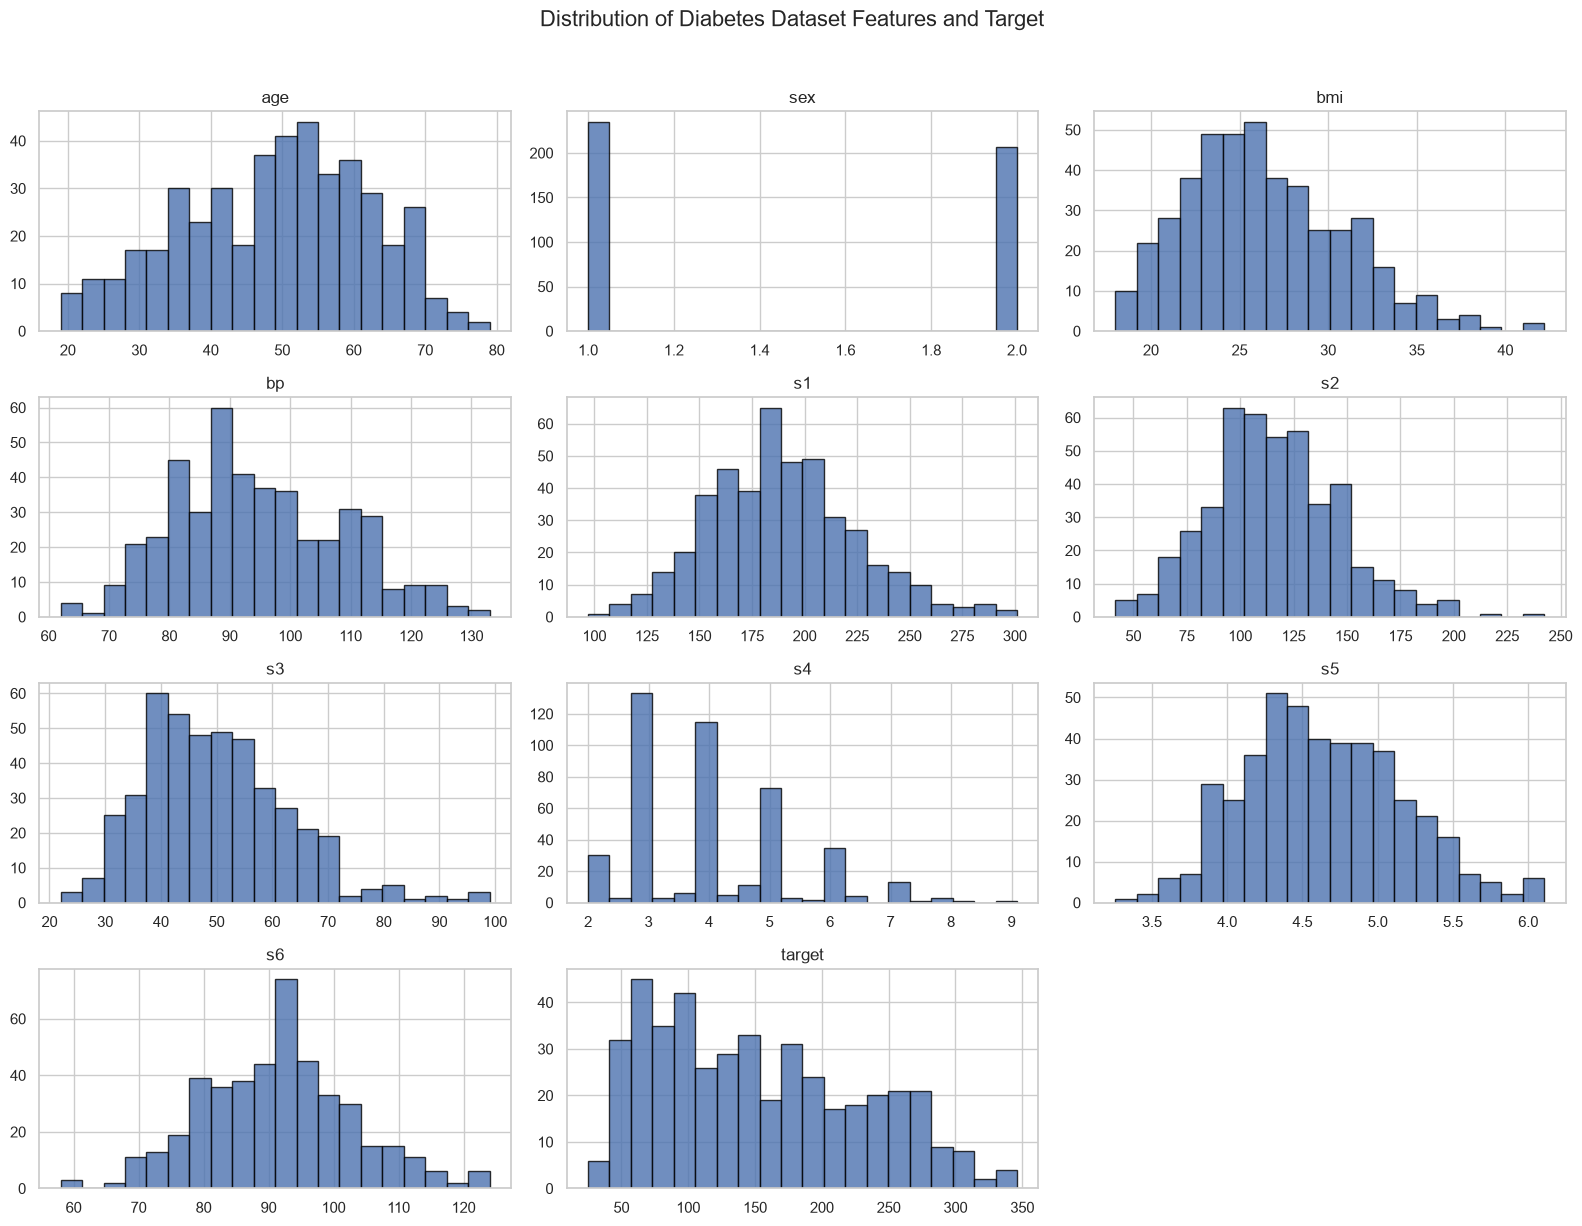

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot distributions of all features and the target
df.hist(
    bins=20,
    figsize=(16, 12),
    edgecolor="black",
    alpha=0.8
)

plt.suptitle(
    "Distribution of Diabetes Dataset Features and Target",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


#### 1.3.4 Initial EDA Findings

The exploratory analysis provides the following observations:

**Dataset Completeness and Quality**
- The dataset contains 442 observations and 11 columns, including 10 predictors and one target variable.
- No missing values or duplicate records were detected.
- All columns are stored numerically. However, `sex` represents two encoded categories and should not be interpreted as a continuous measurement.

**Descriptive Statistics**
- The average patient age is 48.52 years, with ages ranging from 19 to 79.
- The average BMI is 26.38, with values ranging from 18.0 to 42.2.
- The diabetes progression target has a mean of 152.13, a median of 140.50, and a standard deviation of 77.09.
- The progression score ranges from 25 to 346, indicating substantial variation across patients.

**Distribution Analysis**
- BMI is concentrated around the mid-20s, with a right tail representing higher BMI observations.
- Several serum measurements show asymmetric or irregular distributions.
- The target has a skewness of 0.44, indicating a moderately right-skewed distribution.
- Potential extreme observations should be investigated before any data cleaning decisions.

**Implications for Modeling**

The dataset is sufficiently complete to proceed without immediate imputation or duplicate removal. The variation in the target indicates that predicting progression may be challenging. Relationships between individual features and the target must be examined further using scatter plots and correlation analysis.

These observations are descriptive and do not establish causal relationships.



#### 1.3.5 Scatter Plot Analysis

Scatter plots help visualize relationships between individual predictors and the diabetes progression target.

We examine age, BMI, blood pressure, and serum measurement `s5` to investigate whether higher or lower feature values are associated with changes in disease progression.

Linear trend lines are included to make general patterns easier to identify. These lines describe associations and do not establish causation.


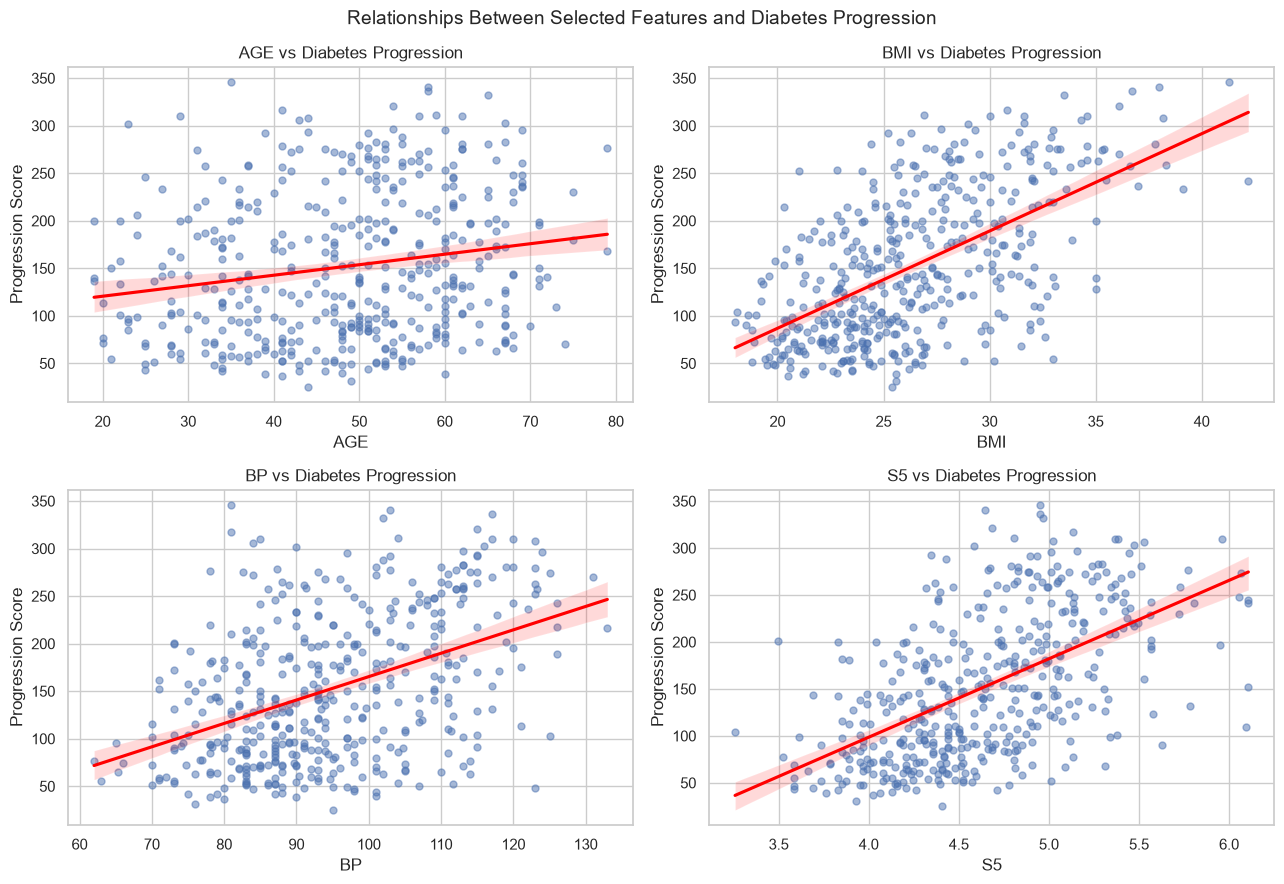

In [7]:
from src.diabetes_eda import DiabetesEDA

# Create an instance of the EDA class
eda = DiabetesEDA(df)

# Visualize relationships
eda.plot_scatter_relationships()


#### 1.3.6 Correlation Analysis

A Pearson correlation matrix is used to measure the strength and direction of linear relationships between numerical variables.

Correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear relationship.
- **0:** No linear relationship.
- **-1:** Perfect negative linear relationship.

We examine correlations with the target to identify potential predictors and correlations between features to identify possible multicollinearity.

Because `sex` is category-coded, its numerical correlation requires careful interpretation. Correlation does not imply causation.


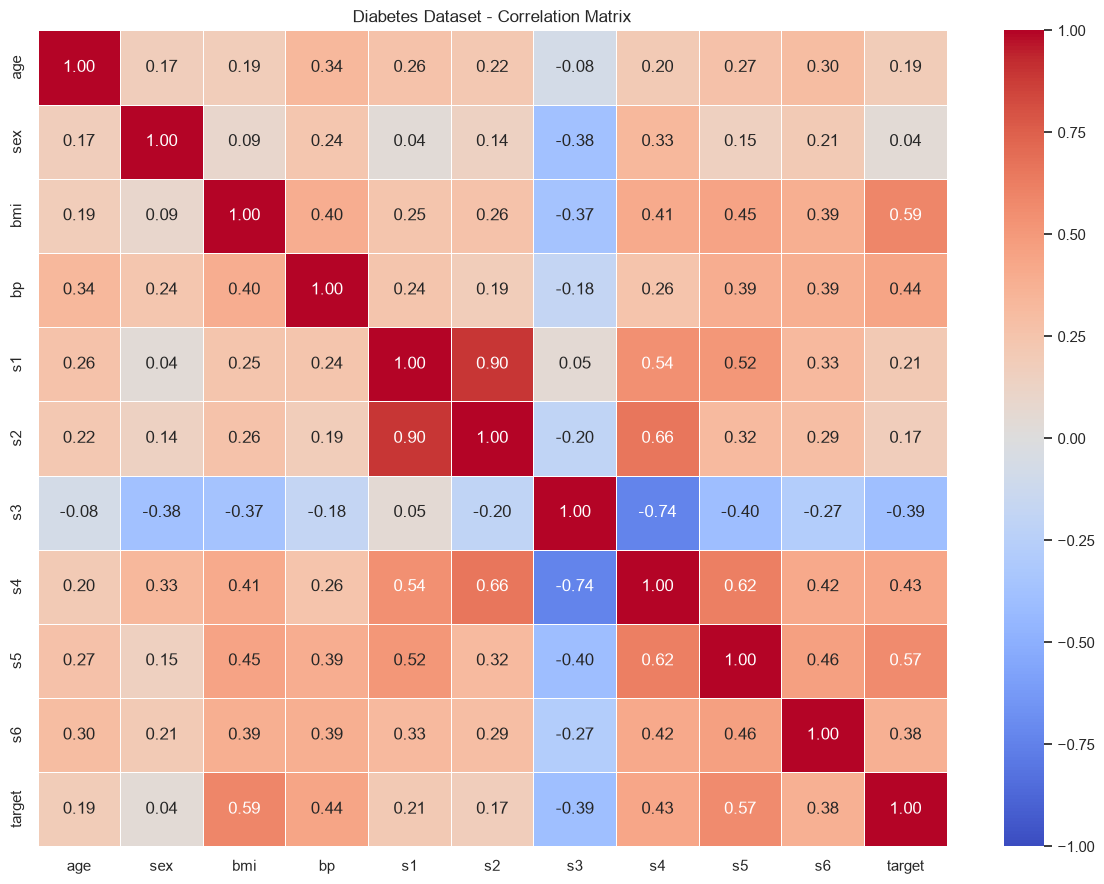

Feature Correlations with Diabetes Progression:


,Correlation with Target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043
s3,-0.395


In [8]:
# Visualize correlation matrix
eda.plot_correlation_matrix()

# Rank correlations with diabetes progression
print("Feature Correlations with Diabetes Progression:")
display(
    eda.get_target_correlations()
    .to_frame(name="Correlation with Target")
    .round(3)
)


#### 1.3.7 Scatter Plot and Correlation Findings

**Scatter Plot Analysis**

The scatter plots reveal differences in how individual patient measurements relate to diabetes progression.

- **BMI:** Shows a clear positive relationship with the target. Patients with higher BMI values generally tend to have higher progression scores, although considerable variation remains.
- **S5:** Also demonstrates a noticeable positive association with disease progression.
- **Blood Pressure (BP):** Shows a moderate positive relationship, suggesting that blood pressure may contribute useful predictive information.
- **Age:** Has a relatively weak positive relationship with progression, indicating limited predictive ability when considered independently.

The considerable scatter around the trend lines suggests that relying on a single feature may not be sufficient for highly accurate predictions.

**Correlation Analysis**

The Pearson correlation matrix provides the following findings:

| Feature | Correlation with Target |
|---------|------------------------:|
| BMI | 0.586 |
| S5 | 0.566 |
| BP | 0.441 |
| S4 | 0.430 |
| S6 | 0.382 |
| S3 | -0.395 |
| Age | 0.188 |
| Sex | 0.043 |

BMI has the strongest positive linear correlation with diabetes progression, followed by S5. This supports using BMI for the univariate polynomial regression models in Part 2.

S3 has the strongest negative correlation with the target, indicating that higher S3 values tend to be associated with lower progression scores.

**Potential Multicollinearity**

The correlation matrix also reveals strong relationships between some predictors:

- S1 and S2: approximately 0.90
- S3 and S4: approximately -0.74

These relationships suggest potential multicollinearity, which can affect the stability and interpretation of regression coefficients.

Feature removal is not automatically necessary. We will consider these relationships when evaluating multivariate models in Part 3.

**Implications for Model Development**

1. BMI is an appropriate starting feature for univariate polynomial regression.
2. Additional features such as S5 and BP may improve predictive performance in multivariate models.
3. Weak individual correlation does not necessarily mean a feature has no predictive value when combined with others.
4. Training and validation results will be used to determine whether increasing model complexity improves generalization.

These results describe statistical associations rather than causal relationships.



#### 1.3.8 Outlier Detection Using the IQR Method

Potential outliers are examined using the Interquartile Range (IQR) method and boxplots.

The IQR is calculated as:

IQR = Q3 - Q1

Values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

The encoded categorical feature `sex` is excluded from this analysis because the IQR method is not appropriate for its category codes.

The target variable is included for descriptive analysis but will not be used to remove observations automatically.

Outliers are not necessarily errors. Extreme patient measurements may represent legitimate clinical observations, so removal or modification requires additional justification.


IQR-Based Outlier Summary:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
Feature,,,,,,,
age,38.25,59.00,20.75,7.12,90.12,0,0.00
bmi,23.20,29.28,6.07,14.09,38.39,3,0.68
bp,84.00,105.00,21.00,52.50,136.50,0,0.00
s1,164.25,209.75,45.50,96.00,278.00,8,1.81
s2,96.05,134.50,38.45,38.37,192.18,7,1.58
s3,40.25,57.75,17.50,14.00,84.00,7,1.58
s4,3.00,5.00,2.00,0.00,8.00,2,0.45
s5,4.28,5.00,0.72,3.20,6.08,4,0.90
s6,83.25,98.00,14.75,61.12,120.12,9,2.04


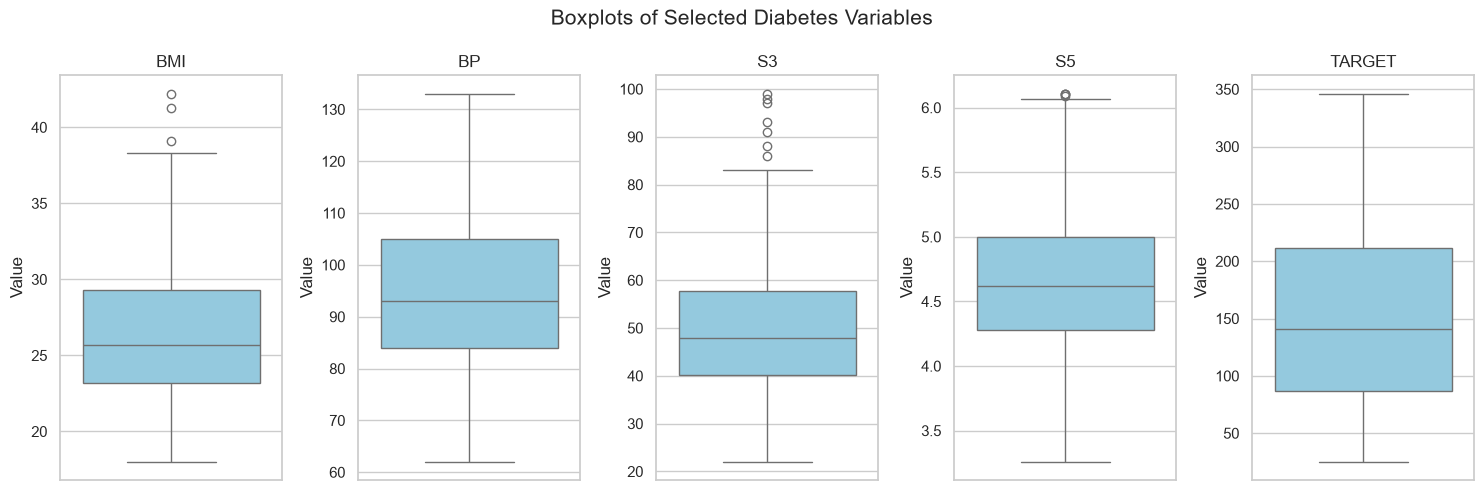

In [9]:

# Generate outlier report using our OOP class
outlier_summary = eda.outlier_report()

print("IQR-Based Outlier Summary:")
display(outlier_summary.round(2))

# Visualize selected variables
eda.plot_boxplots()



#### 1.3.9 Outlier Analysis Findings

The IQR method and boxplots identified several potential outliers in the diabetes dataset.

**Key Findings:**

- BMI contains 3 potential outliers (0.68%).
- S1 contains 8 potential outliers (1.81%).
- S2 and S3 each contain 7 potential outliers (1.58%).
- S4 contains 2 potential outliers (0.45%).
- S5 contains 4 potential outliers (0.90%).
- S6 contains 9 potential outliers (2.04%).
- Age, blood pressure, and the target variable have no outliers under the 1.5 × IQR rule.

The boxplots confirm the presence of several unusually high measurements, particularly for BMI and S3.

However, statistical outliers do not necessarily represent incorrect data. These observations may reflect genuine differences between patients.

Since no evidence of measurement errors has been identified, the outliers will be retained. Their possible influence on model performance will be considered during evaluation.

**Conclusion:** No automatic outlier removal or capping will be performed.



### 1.4 Data Cleaning and Preprocessing Decisions

Before model development, the dataset was examined for missing values, duplicated records, inconsistent data types, and potential outliers.

**Data Quality Assessment:**

| Check | Result | Decision |
|-------|--------|----------|
| Missing values | 0 | No imputation required |
| Duplicate records | 0 | No duplicates to remove |
| Data types | All numeric | No type conversion required |
| Encoded categorical feature | Sex (1 and 2) | Retain binary encoding |
| Potential outliers | Identified in several features | Retain observations |
| Target variable | Continuous numerical score | No target transformation required |

**Cleaning Decisions:**

The dataset is complete and does not require missing-value imputation or duplicate removal.

Although the IQR method identified some extreme observations, these values cannot be assumed to be errors. Therefore, all 442 patient records will be preserved.

The `sex` feature is represented using two numerical codes. Its existing binary encoding will be retained, while recognizing that its values represent categories rather than a continuous quantity.

Feature scaling will be applied within appropriate model pipelines, particularly for distance-based models such as KNN. Any fitted preprocessing transformations will be learned from the training set only to prevent data leakage.

**Final Decision:**

No records or features will be removed during the initial cleaning stage. The original feature values will be retained for model development, and the effects of model complexity and extreme observations will be considered during evaluation.


In [10]:
# Create a clean working copy without modifying the original data
df_clean = df.copy()

# Verify data integrity
assert df_clean.isna().sum().sum() == 0, "Missing values detected"
assert df_clean.duplicated().sum() == 0, "Duplicate records detected"
assert df_clean.shape == df.shape, "Dataset shape changed unexpectedly"

print("Data cleaning verification successful!")
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())
print("All original observations retained:", len(df_clean) == len(df))

Data cleaning verification successful!
Original dataset shape: (442, 11)
Clean dataset shape: (442, 11)
Missing values: 0
Duplicate records: 0
All original observations retained: True
